In [100]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [101]:
df=pd.read_csv(r"C:\Users\Shashank S Khavekar\OneDrive\Desktop\End-to-End\Customer Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [102]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Replacing Blanks with 0 as tenure is 0 and no total charges are records

In [103]:
df['TotalCharges']=df['TotalCharges'].replace(' ','0')
df['TotalCharges']=df['TotalCharges'].astype(float)

In [104]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [105]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [106]:
df.duplicated().sum()

np.int64(0)

In [107]:
df['customerID'].duplicated().sum()

np.int64(0)

<!-- # Converted 0 and 1 Values of senior citizin to yes / no to make it easier to understand  -->

In [108]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({1: 'yes', 0: 'no'})

In [109]:
def con (value):
    if value==1:
        return 'yes'
    else:
        return 'no'

df['SeniorCitizen'] = df['SeniorCitizen'].apply(con)

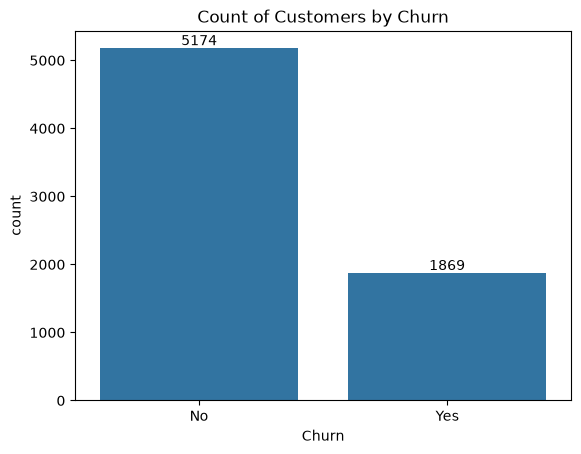

In [110]:
ax=sns.countplot(x='Churn', data=df)

ax.bar_label(ax.containers[0])
plt.title('Count of Customers by Churn')
plt.show()

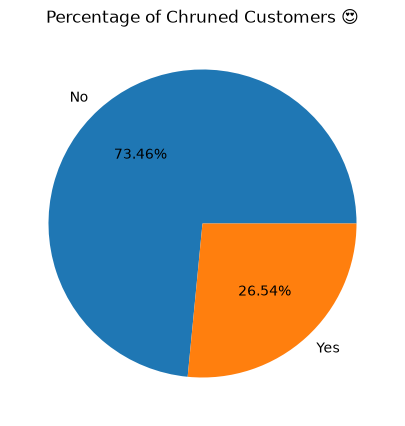

In [111]:
gb=df.groupby('Churn').agg({'Churn':'count'})
gb
plt.figure(figsize=(10,5))
plt.pie(gb['Churn'],labels=gb.index,autopct='%1.2f%%')
plt.title('Percentage of Chruned Customers 😍')
plt.show()

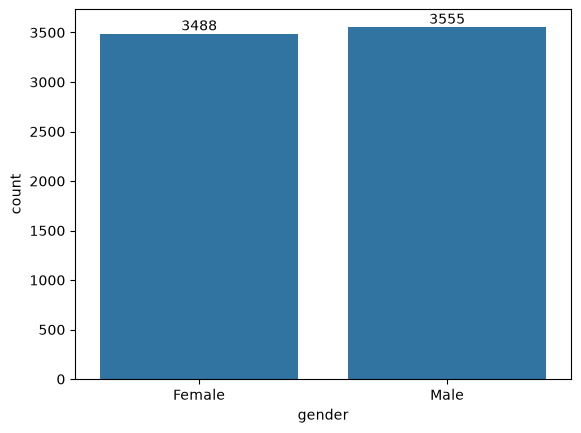

In [112]:
sk=sns.countplot(x='gender',data=df)
sk.bar_label(sk.containers[0])
plt.show()

In [113]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

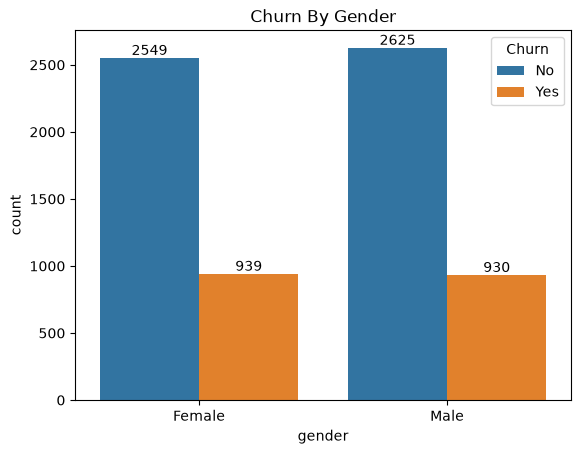

In [114]:
sk=sns.countplot(x='gender', data=df, hue='Churn')
sk.bar_label(sk.containers[0])
sk.bar_label(sk.containers[1])
plt.title('Churn By Gender')
plt.show()

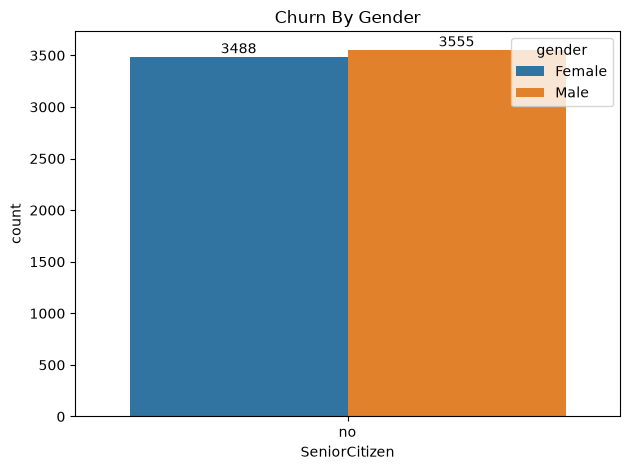

In [115]:
sk=sns.countplot(x='SeniorCitizen', data=df, hue='gender')
sk.bar_label(sk.containers[0])
sk.bar_label(sk.containers[1])
plt.title('Churn By Gender')
plt.tight_layout()
plt.show()

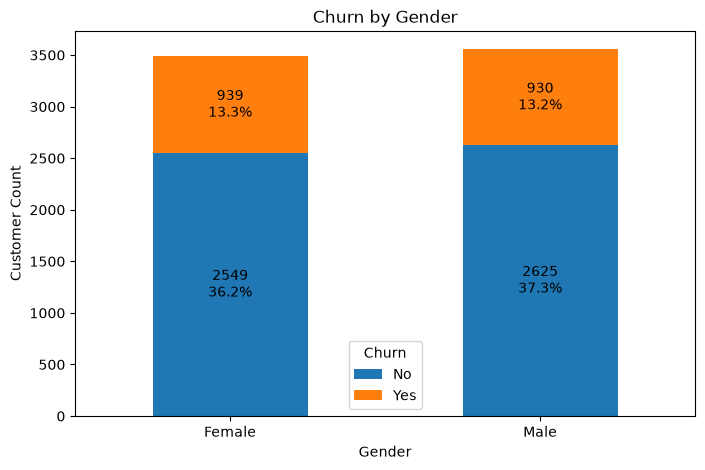

In [116]:
import pandas as pd
import matplotlib.pyplot as plt

ct = pd.crosstab(df['gender'], df['Churn'])

ax = ct.plot(kind='bar', stacked=True, figsize=(8, 5))

total = ct.values.sum()

labels = ct.map(lambda x: f'{x}\n{x / total * 100:.1f}%')

ax.bar_label(ax.containers[0], labels=labels.iloc[:, 0], label_type='center')
ax.bar_label(ax.containers[1], labels=labels.iloc[:, 1], label_type='center')

plt.title('Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Customer Count')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

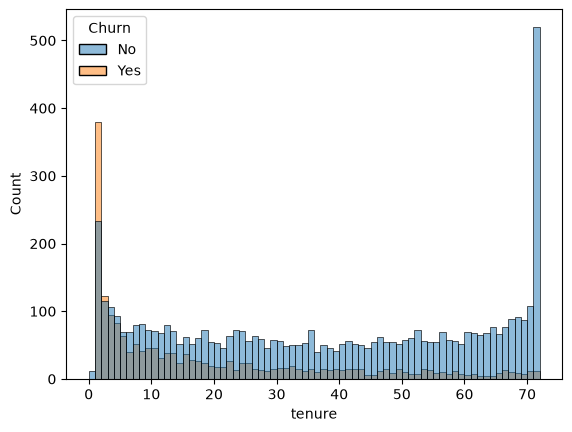

In [ ]:
sns.histplot(x='tenure',data=df,bins=72,hue='Churn')
plt.show()




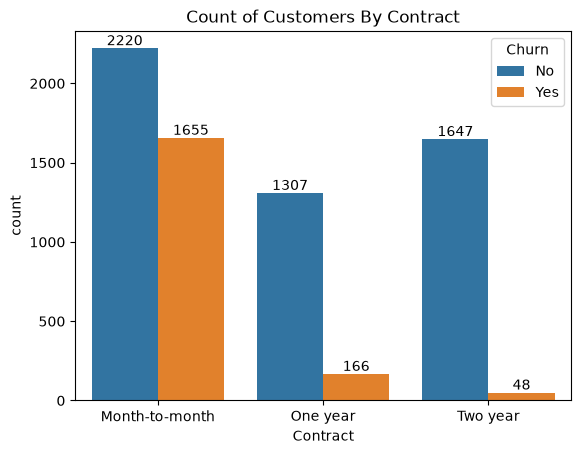

In [129]:
ax=sns.countplot(x='Contract',data=df,hue='Churn')
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title('Count of Customers By Contract')
plt.show()

In [130]:
df.columns.values

<StringArray>
[      'customerID',           'gender',    'SeniorCitizen',
          'Partner',       'Dependents',           'tenure',
     'PhoneService',    'MultipleLines',  'InternetService',
   'OnlineSecurity',     'OnlineBackup', 'DeviceProtection',
      'TechSupport',      'StreamingTV',  'StreamingMovies',
         'Contract', 'PaperlessBilling',    'PaymentMethod',
   'MonthlyCharges',     'TotalCharges',            'Churn']
Length: 21, dtype: str

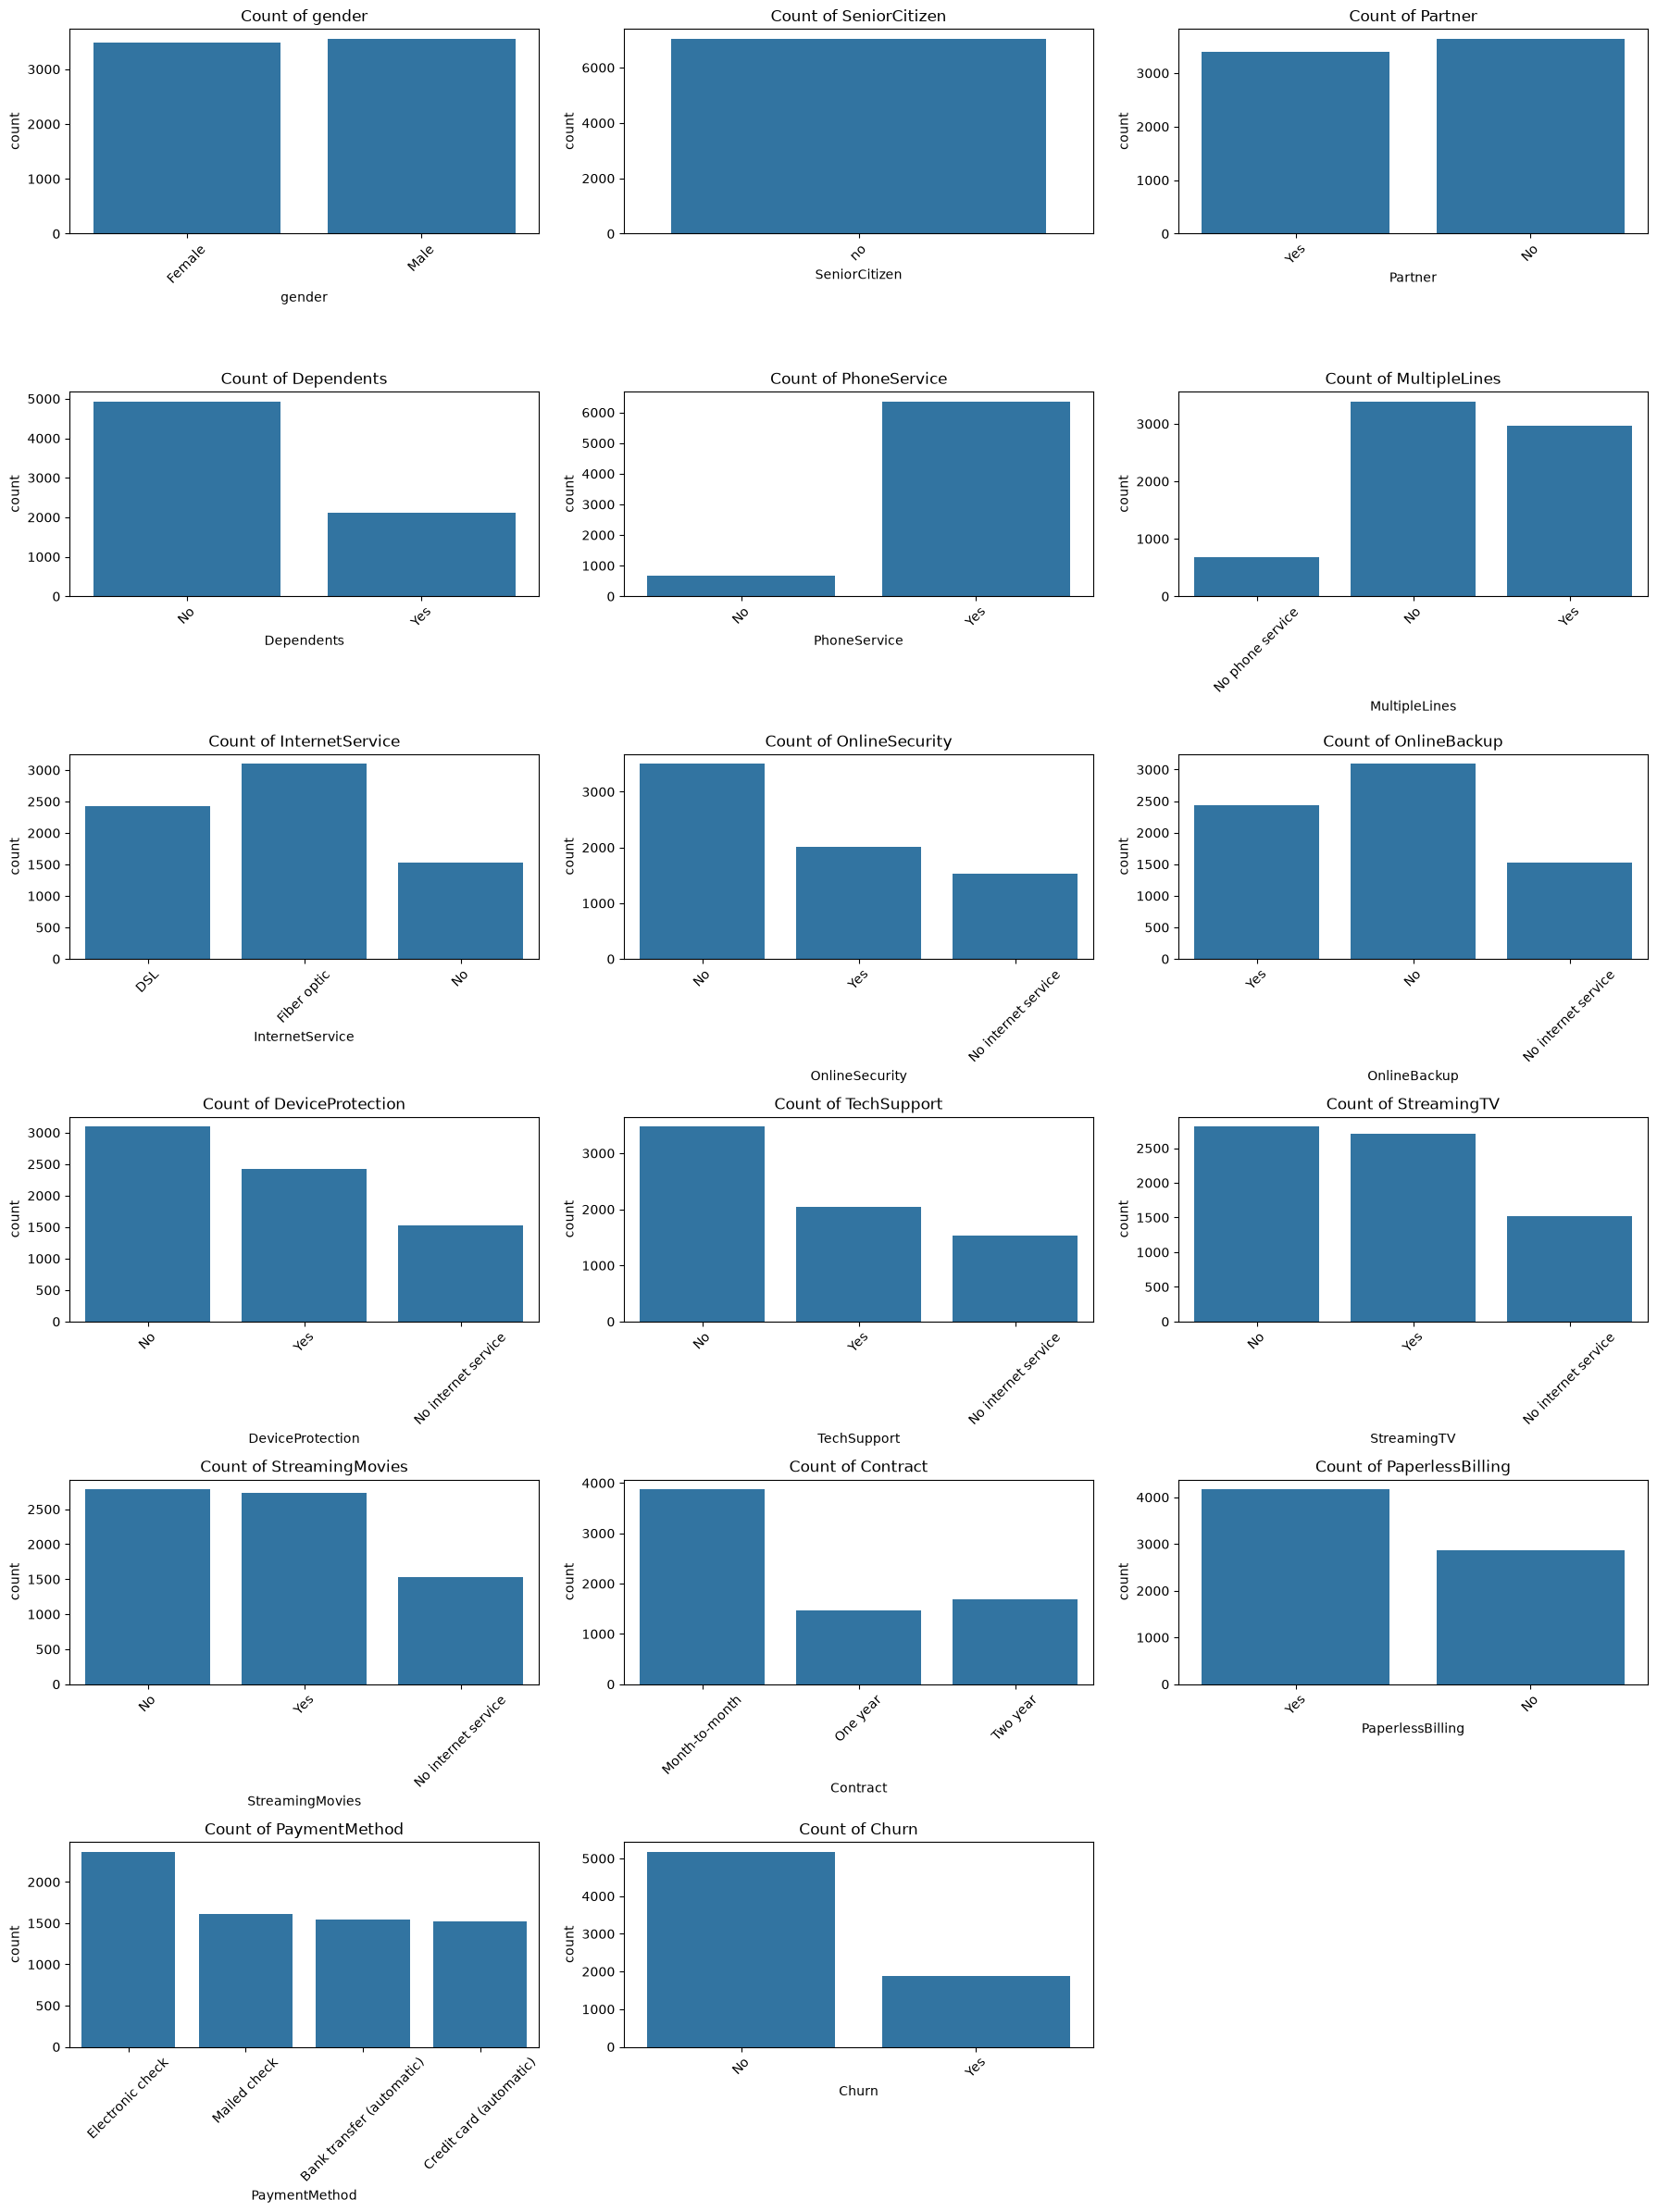

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'
]

fig, axes = plt.subplots(6, 3, figsize=(18, 24))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Count of {col}')
    axes[i].tick_params(axis='x', rotation=45)

# Remove unused subplot spaces
for j in range(len(cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

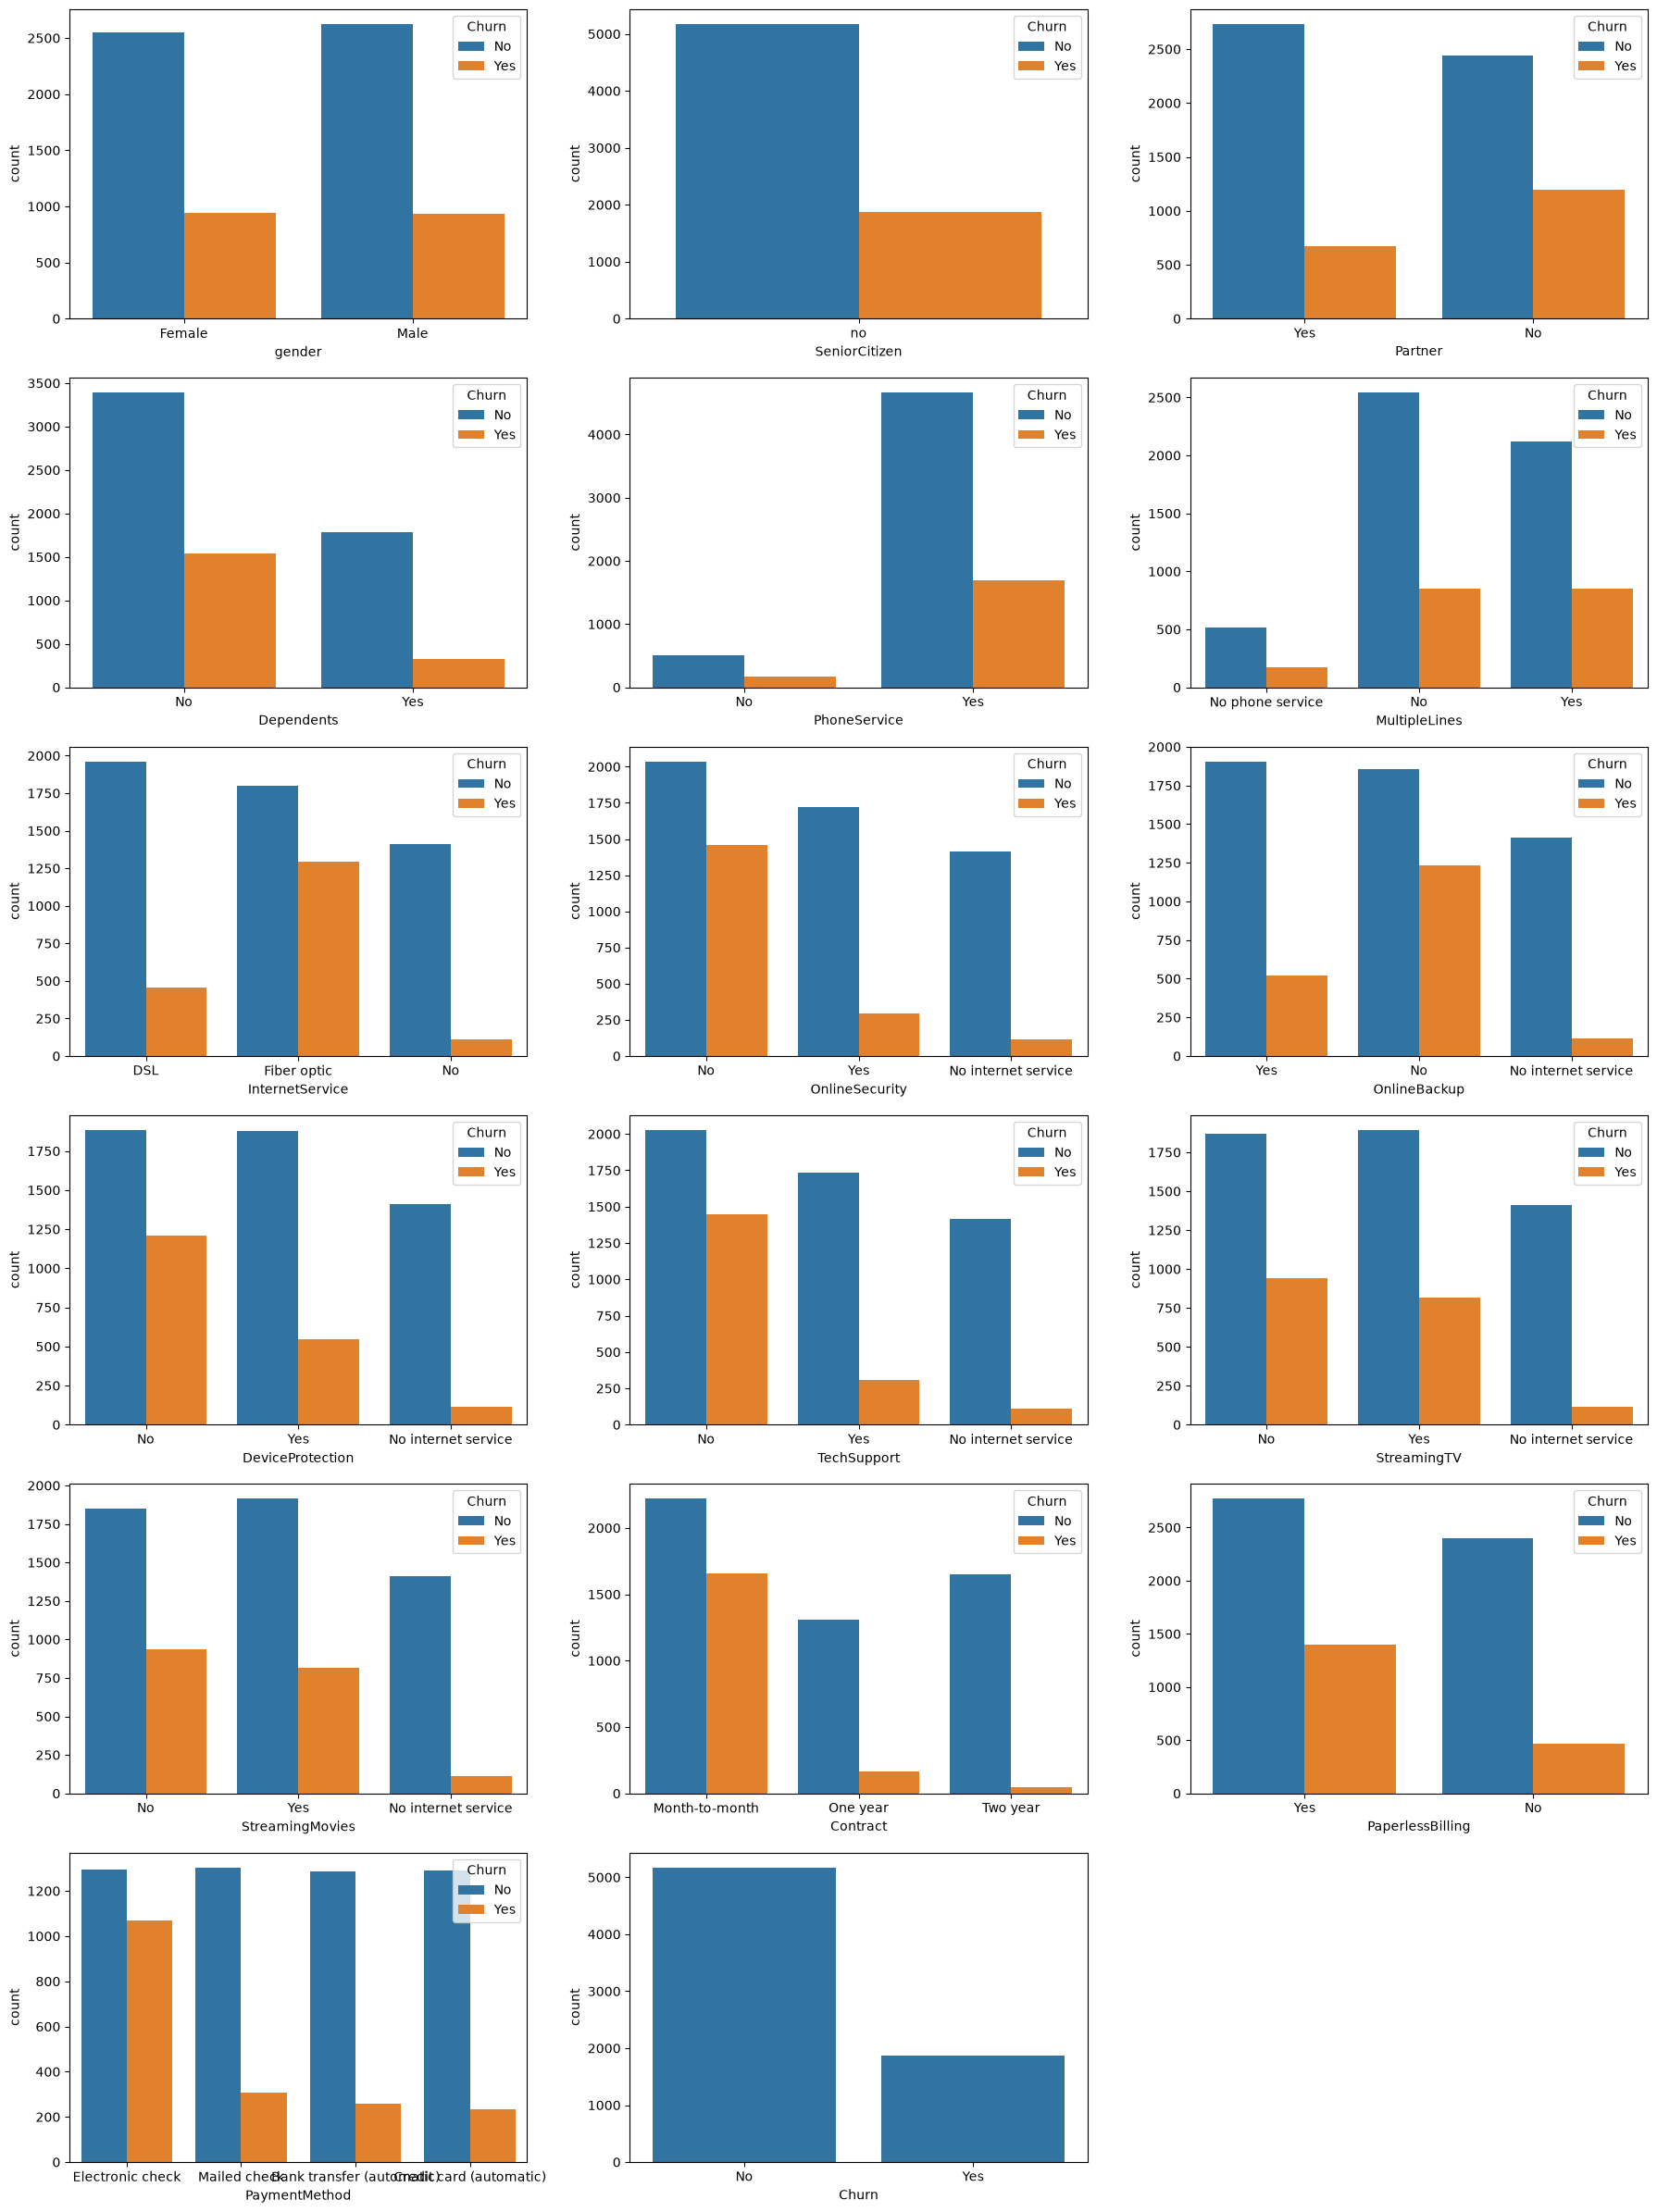

In [131]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(6, 3, figsize=(18, 24))

sns.countplot(data=df, x='gender', hue='Churn', ax=axes[0, 0])
sns.countplot(data=df, x='SeniorCitizen', hue='Churn', ax=axes[0, 1])
sns.countplot(data=df, x='Partner', hue='Churn', ax=axes[0, 2])

sns.countplot(data=df, x='Dependents', hue='Churn', ax=axes[1, 0])
sns.countplot(data=df, x='PhoneService', hue='Churn', ax=axes[1, 1])
sns.countplot(data=df, x='MultipleLines', hue='Churn', ax=axes[1, 2])

sns.countplot(data=df, x='InternetService', hue='Churn', ax=axes[2, 0])
sns.countplot(data=df, x='OnlineSecurity', hue='Churn', ax=axes[2, 1])
sns.countplot(data=df, x='OnlineBackup', hue='Churn', ax=axes[2, 2])

sns.countplot(data=df, x='DeviceProtection', hue='Churn', ax=axes[3, 0])
sns.countplot(data=df, x='TechSupport', hue='Churn', ax=axes[3, 1])
sns.countplot(data=df, x='StreamingTV', hue='Churn', ax=axes[3, 2])

sns.countplot(data=df, x='StreamingMovies', hue='Churn', ax=axes[4, 0])
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[4, 1])
sns.countplot(data=df, x='PaperlessBilling', hue='Churn', ax=axes[4, 2])

sns.countplot(data=df, x='PaymentMethod', hue='Churn', ax=axes[5, 0])
sns.countplot(data=df, x='Churn', ax=axes[5, 1])

fig.delaxes(axes[5, 2])

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Chruned Customers Payment Method ')

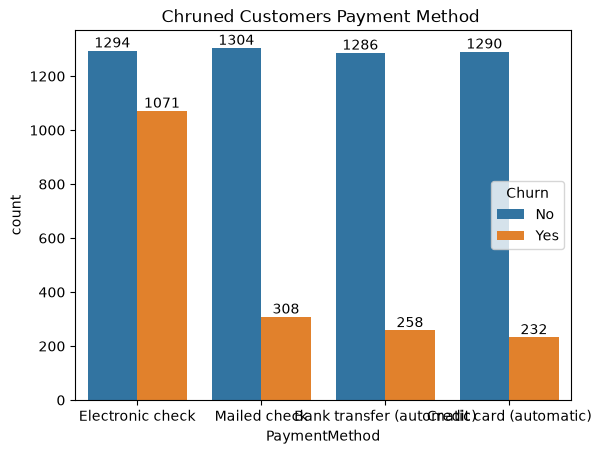

In [134]:
ax=sns.countplot(x='PaymentMethod',data=df,hue='Churn')
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title('Chruned Customers Payment Method ')